In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import torch
import torch.nn as nn

import schnetpack as spk
from schnetpack.datasets import MD17
from schnetpack.datasets.md22 import MD22

from atomistic_deq_ff.model.solvers import fixed_point_iteration, anderson
from atomistic_deq_ff.model.util import init_iterating_schnet
from atomistic_deq_ff.data.util import load_md17_data

from atomistic_deq_ff.loading import load_model

from atomistic_deq_ff.training.util import setup_task
import pytorch_lightning as pl

from atomistic_deq_ff.training.run import train
from atomistic_deq_ff.analysis.molecules import create_batch
import random

from atomistic_deq_ff.common.util import proj_path

import wandb
wandb.init( mode='disabled')

device = 'cuda' if torch.cuda.is_available() else 'cpu'
# device='mps'

In [3]:
def log_memory(prefix=""):
    
    exp,lbl=3,'GB'
    exp,lbl=2,'MB'
    
    current = torch.cuda.memory_allocated() / 1024**exp
    peak = torch.cuda.max_memory_allocated() / 1024**exp
    reserved = torch.cuda.memory_reserved() / 1024**exp
    print(f"{prefix} | Current: {current:.2f}{lbl} | Peak: {peak:.2f}{lbl} | Reserved: {reserved:.2f}{lbl}")
    
    
def get_connectivity(n_atoms, n_neighbours=None, equal=True):
    if n_neighbours is None:
        n_neighbours = n_atoms-1
    if equal:
        # n_neighbours random neighbours for each atom
        connectivity = [(i, j) for i in range(n_atoms) for j in random.sample([k for k in range(n_atoms) if k != i], n_neighbours)]
    else:
        # n_atoms x n_atoms random edges
        n_edges = n_atoms * n_neighbours
        all_pairs = [(i, j) for i in range(n_atoms) for j in range(n_atoms) if i != j]
        connectivity = random.sample(all_pairs, min(n_edges, len(all_pairs)))

    return connectivity

    
log_memory()

 | Current: 0.00MB | Peak: 0.00MB | Reserved: 0.00MB


# Create new model

In [ ]:
nnpot, *_ = init_iterating_schnet(n_z=64, deq_model_inference=True, device=device)

In [6]:
log_memory('After model initialization')
torch.cuda.reset_peak_memory_stats()

After model initialization | Current: 0.36MB | Peak: 0.36MB | Reserved: 2.00MB


# Synthetic 'molecules'

In [ ]:
n_atoms = 10
n_neighbours = 3

equal = True
equal = False

batch = create_batch(pos=n_atoms, Z=None, connectivity=get_connectivity(n_atoms, n_neighbours, equal), device=device)
{v.device for k,v in batch.items()  if type(v) is torch.Tensor}

num edges: 30.0


{device(type='cuda', index=0)}

In [8]:
log_memory('After batch initialization')
torch.cuda.reset_peak_memory_stats()

After batch initialization | Current: 0.36MB | Peak: 0.36MB | Reserved: 2.00MB


In [9]:
out = nnpot(batch)
out.keys()

dict_keys(['z_star', 'back_iterations', 'forw_iterations', 'energy', 'forces', 'forw_res', 'back_res', 'g_bar_star'])

In [10]:
out['forces']

tensor([[-0.0166, -0.1410, -0.1087],
        [-0.0280, -0.0120,  0.0148],
        [-0.0175,  0.0445,  0.0123],
        [-0.0457, -0.0549,  0.0640],
        [ 0.0572, -0.0124,  0.0024],
        [-0.0221,  0.0499, -0.0551],
        [-0.1225, -0.0313,  0.0570],
        [ 0.0075, -0.0174,  0.2208],
        [ 0.2231,  0.1994, -0.3486],
        [-0.0355, -0.0249,  0.1411]], device='cuda:0')

In [11]:
log_memory('After prediction')
torch.cuda.reset_peak_memory_stats()

After prediction | Current: 17.10MB | Peak: 17.36MB | Reserved: 24.00MB


# Peak memory scan over n_atoms (all-to-all connectivity)

In [12]:
num_predecessors = 2
use_deq = True  # nnpot is a DEQ model

n_atoms_list = [5, 10, 20, 30, 50, 75, 100, 150, 200]
peak_memory_MB = []
equal = True
n_neighbours=None

for n_atoms in n_atoms_list:
    connectivity = get_connectivity(n_atoms, n_neighbours=n_neighbours, equal=equal)
    batch = create_batch(pos=n_atoms, Z=None, connectivity=connectivity, device=device)

    torch.cuda.synchronize()
    torch.cuda.reset_peak_memory_stats()

    out = nnpot(batch)

    torch.cuda.synchronize()
    peak_mb = torch.cuda.max_memory_allocated() / 1024**2

    z_star_mb     = out['z_star'].nbytes     / 1024**2 if 'z_star'     in out else 0.
    g_bar_star_mb = out['g_bar_star'].nbytes / 1024**2 if 'g_bar_star' in out else 0.
    if use_deq:
        peak_mb += (z_star_mb + g_bar_star_mb) * (num_predecessors - 1)

    peak_memory_MB.append(peak_mb)
    print(f"n_atoms={n_atoms:4d}  |  n_edges={n_atoms*(n_atoms-1):6d}  |  peak={peak_mb:.2f} MB  (z_star={z_star_mb:.3f}, g_bar_star={g_bar_star_mb:.3f})")
    del out

print("\npeak_memory_MB =", peak_memory_MB)

num edges: 20.0
n_atoms=   5  |  n_edges=    20  |  peak=18.68 MB  (z_star=0.005, g_bar_star=0.005)
num edges: 90.0
n_atoms=  10  |  n_edges=    90  |  peak=20.44 MB  (z_star=0.010, g_bar_star=0.010)
num edges: 380.0
n_atoms=  20  |  n_edges=   380  |  peak=27.56 MB  (z_star=0.020, g_bar_star=0.020)
num edges: 870.0
n_atoms=  30  |  n_edges=   870  |  peak=41.71 MB  (z_star=0.029, g_bar_star=0.029)
num edges: 2450.0
n_atoms=  50  |  n_edges=  2450  |  peak=83.59 MB  (z_star=0.049, g_bar_star=0.049)
num edges: 5550.0
n_atoms=  75  |  n_edges=  5550  |  peak=167.17 MB  (z_star=0.073, g_bar_star=0.073)
num edges: 9900.0
n_atoms= 100  |  n_edges=  9900  |  peak=287.30 MB  (z_star=0.098, g_bar_star=0.098)
num edges: 22350.0
n_atoms= 150  |  n_edges= 22350  |  peak=617.99 MB  (z_star=0.146, g_bar_star=0.146)
num edges: 39800.0
n_atoms= 200  |  n_edges= 39800  |  peak=1086.22 MB  (z_star=0.195, g_bar_star=0.195)

peak_memory_MB = [18.68017578125, 20.43603515625, 27.55908203125, 41.7060546875,

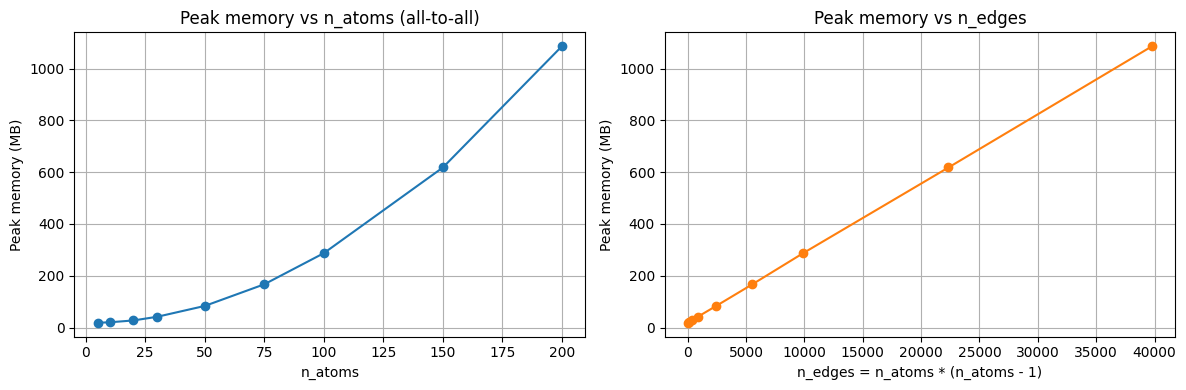

In [13]:
import matplotlib.pyplot as plt
import numpy as np

n_edges_list = [n * (n - 1) for n in n_atoms_list]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# vs n_atoms
axes[0].plot(n_atoms_list, peak_memory_MB, 'o-')
axes[0].set_xlabel('n_atoms')
axes[0].set_ylabel('Peak memory (MB)')
axes[0].set_title('Peak memory vs n_atoms (all-to-all)')
axes[0].grid(True)

# vs n_edges (quadratic in n_atoms)
axes[1].plot(n_edges_list, peak_memory_MB, 'o-', color='tab:orange')
axes[1].set_xlabel('n_edges = n_atoms * (n_atoms - 1)')
axes[1].set_ylabel('Peak memory (MB)')
axes[1].set_title('Peak memory vs n_edges')
axes[1].grid(True)

plt.tight_layout()
plt.show()

# Peak memory scan: AtomisticRepresentationClass × use_deq × n_interactions

In [14]:
import gc

for var in ['nnpot', 'batch', 'b', 'out', 'm', 'molecule_data', 'val_loader', 'train_loader']:
    if var in globals():
        del globals()[var]

gc.collect()
torch.cuda.empty_cache()
log_memory('After cleanup')

After cleanup | Current: 0.28MB | Peak: 0.58MB | Reserved: 2.00MB


### Vary n_atoms

In [15]:
from schnetpack.representation import PaiNN, SO3net, SchNet
import gc

n_atoms_list_scan = [5, 10, 20, 30, 50, 75, 100]
equal = True
equal = False
n_neighbours = None

use_deqs = [True, False]
rep_classes   = [SchNet, PaiNN, SO3net]

# use_deqs = [True]
rep_classes   = [SO3net]

n_interactions_per_deq = {True: [1], False: [1, 3, 5]}

results_grid = {}

for RepClass in rep_classes:
    for use_deq in use_deqs:
        for n_int in n_interactions_per_deq[use_deq]:
            key = (RepClass.__name__, use_deq, n_int)
            print(f"\n--- {RepClass.__name__}  use_deq={use_deq}  n_interactions={n_int} ---")
            try:
                m, *_ = init_iterating_schnet(
                    n_z=64, deq_model_inference=True, device=device,
                    AtomisticRepresentationClass=RepClass,
                    use_deq=use_deq,
                    n_interactions=n_int,
                )
            except Exception as e:
                print(f"  init failed: {e}")
                continue

            peaks = []
            for n_atoms in n_atoms_list_scan:
                connectivity = get_connectivity(n_atoms, n_neighbours=n_neighbours, equal=equal)
                connectivity = [(0,1)]
                b = create_batch(pos=n_atoms, Z=None, connectivity=connectivity, device=device)
                torch.cuda.synchronize()
                torch.cuda.reset_peak_memory_stats()
                base_alloc = torch.cuda.memory_allocated()
                try:
                    out = m(b)
                except Exception as e:
                    print(f"  forward failed at n_atoms={n_atoms}: {e}")
                    peaks.append(float('nan'))
                    del b
                    continue
                torch.cuda.synchronize()
                peak_mb = (torch.cuda.max_memory_allocated() - base_alloc) / 1024**2
                peaks.append(peak_mb)
                print(f"  n_atoms={n_atoms:4d} | incremental peak={peak_mb:.2f} MB")
                del out, b
                gc.collect()
                torch.cuda.empty_cache()

            results_grid[key] = peaks
            del m
            gc.collect()
            torch.cuda.empty_cache()

print("\nDone.")


--- SO3net  use_deq=True  n_interactions=1 ---
num edges: 1.0
  n_atoms=   5 | incremental peak=17.24 MB
num edges: 1.0
  n_atoms=  10 | incremental peak=2.90 MB
num edges: 1.0
  n_atoms=  20 | incremental peak=4.43 MB
num edges: 1.0
  n_atoms=  30 | incremental peak=5.96 MB
num edges: 1.0
  n_atoms=  50 | incremental peak=9.73 MB
num edges: 1.0
  n_atoms=  75 | incremental peak=13.70 MB
num edges: 1.0
  n_atoms= 100 | incremental peak=17.19 MB

--- SO3net  use_deq=False  n_interactions=1 ---
num edges: 1.0
  n_atoms=   5 | incremental peak=1.57 MB
num edges: 1.0
  n_atoms=  10 | incremental peak=1.95 MB
num edges: 1.0
  n_atoms=  20 | incremental peak=3.45 MB
num edges: 1.0
  n_atoms=  30 | incremental peak=5.08 MB
num edges: 1.0
  n_atoms=  50 | incremental peak=9.05 MB
num edges: 1.0
  n_atoms=  75 | incremental peak=13.12 MB
num edges: 1.0
  n_atoms= 100 | incremental peak=16.48 MB

--- SO3net  use_deq=False  n_interactions=3 ---
num edges: 1.0
  n_atoms=   5 | incremental peak=2.

In [16]:
col_w = 9
header = f"{'rep':<12} {'use_deq':<8} {'n_int':<6}" + "".join(f"{n:>{col_w}}" for n in n_atoms_list_scan)
print(header)
print("-" * len(header))
for (rep_name, use_deq, n_int), peaks in results_grid.items():
    row = f"{rep_name:<12} {str(use_deq):<8} {n_int:<6}"
    row += "".join(f"{p:>{col_w}.1f}" if not (p != p) else f"{'nan':>{col_w}}" for p in peaks)
    print(row)

rep          use_deq  n_int         5       10       20       30       50       75      100
-------------------------------------------------------------------------------------------
SO3net       True     1           2.1      2.9      4.4      6.0      9.7     13.7     17.2
SO3net       False    1           1.6      1.9      3.4      5.1      9.0     13.1     16.5
SO3net       False    3           2.6      4.4      8.1     11.8     19.9     29.2     37.7
SO3net       False    5           4.1      7.0     12.8     18.5     31.6     45.5     59.0


### Vary n_atoms, n_edges

In [ ]:
from schnetpack.representation import PaiNN, SO3net, SchNet
import gc

num_predecessors = 2

n_atoms_list_scan = [2, 100, 1000, 10000]
n_edges_list_scan = [1, 100, 1000, 10000]

use_deqs = [True, False]
rep_classes   = [SchNet, PaiNN, SO3net]

# use_deqs = [True]
rep_classes   = [SO3net]

n_interactions_per_deq = {True: [1], False: [1, 3, 5]}

results_grid = {}

for RepClass in rep_classes:
    for use_deq in use_deqs:
        for n_int in n_interactions_per_deq[use_deq]:
            print(f"\n--- {RepClass.__name__}  use_deq={use_deq}  n_interactions={n_int} ---")
            try:
                m, *_ = init_iterating_schnet(
                    n_z=64, deq_model_inference=True, device=device,
                    AtomisticRepresentationClass=RepClass,
                    use_deq=use_deq,
                    n_interactions=n_int,
                )
            except Exception as e:
                print(f"  init failed: {e}")
                continue

            peaks_by_edges = {n_edges: [] for n_edges in n_edges_list_scan}
            for n_atoms in n_atoms_list_scan:
                for n_edges in n_edges_list_scan:
                    connectivity = [(0, 1), (1, 0)] * n_edges
                    b = create_batch(pos=n_atoms, Z=None, connectivity=connectivity, device=device)
                    torch.cuda.synchronize()
                    torch.cuda.reset_peak_memory_stats()
                    base_alloc = torch.cuda.memory_allocated()
                    try:
                        out = m(b)
                    except Exception as e:
                        print(f"  forward failed at n_atoms={n_atoms}, n_edges={n_edges}: {e}")
                        peaks_by_edges[n_edges].append(float('nan'))
                        del b
                        continue
                    torch.cuda.synchronize()
                    peak_mb = (torch.cuda.max_memory_allocated() - base_alloc) / 1024**2

                    z_star_mb     = out['z_star'].nbytes     / 1024**2 if 'z_star'     in out else 0.
                    g_bar_star_mb = out['g_bar_star'].nbytes / 1024**2 if 'g_bar_star' in out else 0.
                    if use_deq:
                        peak_mb += (z_star_mb + g_bar_star_mb) * (num_predecessors - 1)

                    peaks_by_edges[n_edges].append(peak_mb)
                    print(f"  n_atoms={n_atoms:6d}  n_edges={n_edges:6d} | peak={peak_mb:.2f} MB  (z_star={z_star_mb:.3f}, g_bar_star={g_bar_star_mb:.3f})")
                    del out, b
                    gc.collect()
                    torch.cuda.empty_cache()

            for n_edges, peaks in peaks_by_edges.items():
                results_grid[(RepClass.__name__, use_deq, n_int, n_edges)] = peaks
            del m
            gc.collect()
            torch.cuda.empty_cache()

print("\nDone.")

In [ ]:
col_w = 9
header = f"{'rep':<12} {'use_deq':<8} {'n_int':<6} {'n_edges':<8}" + "".join(f"{n:>{col_w}}" for n in n_atoms_list_scan)
print(header)
print("-" * len(header))
for (rep_name, use_deq, n_int, n_edges), peaks in results_grid.items():
    row = f"{rep_name:<12} {str(use_deq):<8} {n_int:<6} {n_edges:<8}"
    row += "".join(f"{p:>{col_w}.1f}" if p == p else f"{'nan':>{col_w}}" for p in peaks)
    print(row)

rep          use_deq  n_int  n_edges         2      100     1000    10000
-------------------------------------------------------------------------
SO3net       True     1      1             2.0     17.5    169.2   1683.4
SO3net       True     1      100          70.3     85.8    239.8   1751.7
SO3net       True     1      1000        707.9    718.2    868.5   2381.2
SO3net       True     1      10000      6989.6   6996.6   7073.8   8584.3
SO3net       False    1      1             1.5     16.6    163.7   1630.2
SO3net       False    1      100          67.3     79.1    197.4   1664.5
SO3net       False    1      1000        678.8    691.3    799.9   1979.2
SO3net       False    1      10000      6704.1   6716.5   6825.4   7907.1
SO3net       False    3      1             2.5     38.4    373.3   3707.0
SO3net       False    3      100         169.1    201.2    508.0   3843.3
SO3net       False    3      1000       1704.1   1740.7   2035.2   5076.8
SO3net       False    3      10000    

In [ ]:
# Check additivity: mem(n, e) ≈ mem(n, e0) + mem(n0, e) - mem(n0, e0)
# where n0 = n_atoms_list_scan[0], e0 = n_edges_list_scan[0]
n0, e0 = n_atoms_list_scan[0], n_edges_list_scan[0]

print(f"Additivity check (ref: n_atoms={n0}, n_edges={e0})")
print(f"{'key':<40} {'n_atoms':>8} {'n_edges':>8} {'actual':>10} {'predicted':>10} {'resid%':>8}")
print("-" * 90)

for (rep, use_deq, n_int, n_edges), peaks in results_grid.items():
    # get ref rows
    ref_n   = results_grid.get((rep, use_deq, n_int, e0))   # mem(n, e0)
    ref_e   = results_grid.get((rep, use_deq, n_int, n_edges))  # same row — need mem(n0, e)
    ref_n0e = results_grid.get((rep, use_deq, n_int, e0))   # mem(n0, e0)
    if ref_n is None or ref_e is None:
        continue
    mem_n0_e0 = ref_n0e[0]  # mem(n0, e0)
    for i, n_atoms in enumerate(n_atoms_list_scan):
        actual = peaks[i]
        if actual != actual: continue
        mem_n_e0   = ref_n[i]           # mem(n, e0)
        mem_n0_e   = ref_e[0]           # mem(n0, e)  — n0 is index 0
        predicted  = mem_n_e0 + mem_n0_e - mem_n0_e0
        resid_pct  = 100 * (actual - predicted) / predicted if predicted else float('nan')
        if n_atoms != n0 and n_edges != e0:  # skip trivial cases
            print(f"{str((rep,use_deq,n_int,n_edges)):<40} {n_atoms:>8} {n_edges:>8} {actual:>10.1f} {predicted:>10.1f} {resid_pct:>7.1f}%")

Additivity check (ref: n_atoms=2, n_edges=1)
key                                       n_atoms  n_edges     actual  predicted   resid%
------------------------------------------------------------------------------------------
('SO3net', True, 1, 100)                      100      100       85.8       85.8     0.0%
('SO3net', True, 1, 100)                     1000      100      239.8      237.5     0.9%
('SO3net', True, 1, 100)                    10000      100     1751.7     1751.7    -0.0%
('SO3net', True, 1, 1000)                     100     1000      718.2      723.4    -0.7%
('SO3net', True, 1, 1000)                    1000     1000      868.5      875.1    -0.8%
('SO3net', True, 1, 1000)                   10000     1000     2381.2     2389.3    -0.3%
('SO3net', True, 1, 10000)                    100    10000     6996.6     7005.1    -0.1%
('SO3net', True, 1, 10000)                   1000    10000     7073.8     7156.8    -1.2%
('SO3net', True, 1, 10000)                  10000    1

In [ ]:
col_w = 9
header = f"{'rep':<12} {'use_deq':<8} {'n_int':<6}" + "".join(f"{n:>{col_w}}" for n in n_atoms_list_scan)
print(header)
print("-" * len(header))
for (rep_name, use_deq, n_int), peaks in results_grid.items():
    row = f"{rep_name:<12} {str(use_deq):<8} {n_int:<6}"
    row += "".join(f"{p:>{col_w}.1f}" if not (p != p) else f"{'nan':>{col_w}}" for p in peaks)
    print(row)

rep          use_deq  n_int         5       10       20       30       50       75      100
-------------------------------------------------------------------------------------------
SchNet       True     1           1.3      2.1      5.6     11.6     31.1     70.2    125.5
SchNet       False    1           1.1      1.7      7.0     15.9     44.6    101.1    187.0
SchNet       False    3           1.3      3.1     12.7     28.8     83.3    184.6    337.4
SchNet       False    5           1.4      4.4     18.4     41.7    121.0    268.1    486.1
PaiNN        True     1           1.6      3.3     10.4     24.5     66.3    149.6    269.5
PaiNN        False    1           1.3      2.5     10.1     23.4     63.4    142.8    260.9
PaiNN        False    3           1.7      5.4     22.2     50.9    137.3    307.5    553.0
PaiNN        False    5           2.1      8.3     34.4     78.8    210.0    472.2    845.7
SO3net       True     1           8.7     33.7    140.3    313.2    867.4   1945

# MD17/22 molecules

In [ ]:
from atomistic_deq_ff.data.info import molecule_to_atomic_numbers
from atomistic_deq_ff.md.util import get_atoms
from schnetpack.representation import PaiNN, SO3net, SchNet
from atomistic_deq_ff.analysis.molecules import create_batch
import random
import gc

In [5]:

print(1)

num_predecessors = 2
molecule_idx = 5000

# Clean-measurement knobs.
N_WARMUP = 1   # discarded forward(s) per (model, molecule): absorbs first-call
               # cuDNN/Inductor autotune + lazy CUDA-allocator growth so they
               # don't inflate the measured peak.
N_REPEAT = 3   # measured forwards; we take the MIN peak (min rejects transient
               # allocator/autotune noise better than mean).

use_deqs = [True, False]
rep_classes = [
    SchNet, 
    PaiNN, 
    SO3net, 
]
# use_deqs = [True]
# rep_classes = [SO3net]
n_interactions_per_deq = {True: [1], False: [1, 3, 5]}

results_mol = {}   # (molecule, rep_name, use_deq, n_int) -> peak_mb
mol_info    = {}   # molecule -> {'n_atoms': int, 'n_edges': int}


def measure_peak_mb(m, b, use_deq, num_predecessors):
    """Min-over-repeats incremental peak (MB) of one forward.

    Clean-measurement contract:
      * a warmup forward is discarded first (autotune / allocator growth);
      * peak is measured relative to a base taken right after the reset, so
        the number is the *activation* memory of the forward, excluding the
        already-resident model + batch;
      * the warmstart carry is MEASURED, not arithmetic: we actually clone the
        converged z*/g_bar* (num_predecessors-1) times INSIDE the measured
        region (deq only), so those buffers are real CUDA allocations counted
        by max_memory_allocated — exactly as large as the MD warmstart carry.
    """
    # Warmup — discarded.
    for _ in range(N_WARMUP):
        out = m(b)
        del out
    gc.collect(); torch.cuda.empty_cache()

    peaks, z_mb, g_mb = [], 0., 0.
    for _ in range(N_REPEAT):
        torch.cuda.synchronize()
        torch.cuda.reset_peak_memory_stats()
        base_alloc = torch.cuda.memory_allocated()
        out = m(b)
        # Materialize the warmstart carry as real allocations (deq only).
        carry = []
        if use_deq:
            for key in ('z_star', 'g_bar_star'):
                if key in out and out[key] is not None:
                    for _p in range(num_predecessors - 1):
                        carry.append(out[key].detach().clone())
            z_mb = out['z_star'].nbytes     / 1024**2 if 'z_star'     in out else 0.
            g_mb = out['g_bar_star'].nbytes / 1024**2 if 'g_bar_star' in out else 0.
        torch.cuda.synchronize()
        peaks.append((torch.cuda.max_memory_allocated() - base_alloc) / 1024**2)
        del out, carry
        gc.collect(); torch.cuda.empty_cache()
    return min(peaks), z_mb, g_mb


# Build batches first, collect mol_info
molecules_ok = []
for molecule in molecule_to_atomic_numbers:
    try:
        atoms = get_atoms(molecule, molecule_idx)
        b = create_batch(
            pos=torch.from_numpy(atoms.positions).to(torch.float32),
            Z=torch.from_numpy(atoms.numbers),
            connectivity=5.,
            device=device,
            return_zts=False,
        )
        mol_info[molecule] = {
            'n_atoms': int(b['_atomic_numbers'].shape[0]),
            'n_edges': int(b['_idx_i'].shape[0]),
        }
        molecules_ok.append(molecule)
        del b
    except Exception as e:
        print(f'  skipping {molecule}: {e}')

# Sort by n_atoms first, then n_edges
molecules_ok.sort(key=lambda m: (mol_info[m]['n_atoms'], mol_info[m]['n_edges']))
# molecules_ok = [molecules_ok[0], molecules_ok[-1]]

print('Molecules (sorted):')
for m in molecules_ok:
    print(f'  {m:<30} n_atoms={mol_info[m]["n_atoms"]:4d}  n_edges={mol_info[m]["n_edges"]:5d}')

for RepClass in rep_classes:
    for use_deq in use_deqs:
        for n_int in n_interactions_per_deq[use_deq]:
            print(f'\n--- {RepClass.__name__}  use_deq={use_deq}  n_interactions={n_int} ---')
            try:
                m, *_ = init_iterating_schnet(
                    n_z=64, deq_model_inference=True, device=device,
                    AtomisticRepresentationClass=RepClass,
                    use_deq=use_deq,
                    n_interactions=n_int,
                )
            except Exception as e:
                print(f'  init failed: {e}')
                continue

            for molecule in molecules_ok:
                atoms = get_atoms(molecule, molecule_idx)
                b = create_batch(
                    pos=torch.from_numpy(atoms.positions).to(torch.float32),
                    Z=torch.from_numpy(atoms.numbers),
                    connectivity=5.,
                    device=device,
                    return_zts=False,
                )
                try:
                    peak_mb, z_star_mb, g_bar_star_mb = measure_peak_mb(
                        m, b, use_deq, num_predecessors)
                except Exception as e:
                    print(f'  forward failed for {molecule}: {e}')
                    results_mol[(molecule, RepClass.__name__, use_deq, n_int)] = float('nan')
                    del b
                    gc.collect(); torch.cuda.empty_cache()
                    continue
                results_mol[(molecule, RepClass.__name__, use_deq, n_int)] = peak_mb
                n_at = mol_info[molecule]['n_atoms']
                n_ed = mol_info[molecule]['n_edges']
                print(f'  {molecule:<25} n_atoms={n_at:4d}  n_edges={n_ed:5d} | peak={peak_mb:.2f} MB  (z*={z_star_mb:.3f}, g*={g_bar_star_mb:.3f})')
                del b
                gc.collect()
                torch.cuda.empty_cache()

            del m
            gc.collect()
            torch.cuda.empty_cache()

print('\nDone.')


1
Molecules (sorted):
  ethanol                        n_atoms=   9  n_edges=   72
  malonaldehyde                  n_atoms=   9  n_edges=   72
  benzene                        n_atoms=  12  n_edges=  128
  uracil                         n_atoms=  12  n_edges=  128
  toluene                        n_atoms=  15  n_edges=  194
  salicylic_acid                 n_atoms=  16  n_edges=  212
  naphthalene                    n_atoms=  18  n_edges=  256
  paracetamol                    n_atoms=  20  n_edges=  278
  aspirin                        n_atoms=  21  n_edges=  302
  azobenzene                     n_atoms=  24  n_edges=  322
  Ac-Ala3-NHMe                   n_atoms=  42  n_edges=  868
  DHA                            n_atoms=  56  n_edges= 1072
  AT-AT                          n_atoms=  60  n_edges= 1036
  stachyose                      n_atoms=  87  n_edges= 2306
  AT-AT-CG-CG                    n_atoms= 118  n_edges= 2528
  buckyball-catcher              n_atoms= 148  n_edges= 4550
  

/tmp/ipykernel_1893219/2499621467.py:32: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels(ax.get_yticklabels(), fontsize=10)
/tmp/ipykernel_1893219/2499621467.py:32: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels(ax.get_yticklabels(), fontsize=10)
/tmp/ipykernel_1893219/2499621467.py:32: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels(ax.get_yticklabels(), fontsize=10)


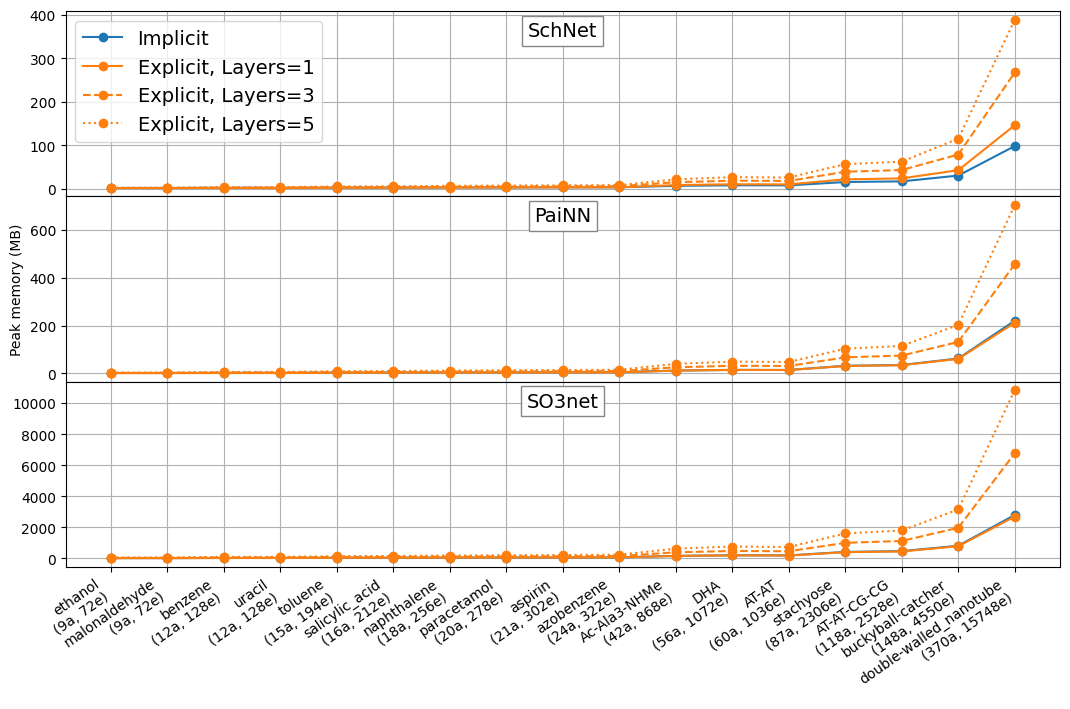

In [ ]:
import matplotlib.pyplot as plt

color_deq = {True: 'tab:blue', False: 'tab:orange'}
dash_nint = {1: '-', 3: '--', 5: ':'}
label_deq = {True: 'Implicit', False: 'Explicit'}

scale = .6

fig, axes = plt.subplots(len(rep_classes), 1, figsize=(scale * 18, scale * 4 * len(rep_classes)), sharex=True, gridspec_kw={'hspace': 0})
if len(rep_classes) == 1:
    axes = [axes]

xs = list(range(len(molecules_ok)))
tick_labels = [f"{m}\n({mol_info[m]['n_atoms']}a, {mol_info[m]['n_edges']}e)" for m in molecules_ok]

for row, RepClass in enumerate(rep_classes):
    ax = axes[row]
    ax.set_title(RepClass.__name__, y=1.0, pad=-18, loc='center', fontsize=14,
             bbox=dict(facecolor='white', alpha=0.95, edgecolor='grey', pad=4))
    ax.grid(True)
    for use_deq in use_deqs:
        for n_int in n_interactions_per_deq[use_deq]:
            ys = [results_mol.get((m, RepClass.__name__, use_deq, n_int), float('nan')) for m in molecules_ok]
            if use_deq:
                label = label_deq[use_deq]
            else:
                label = f"{label_deq[use_deq]}, Layers={n_int}"
            ax.plot(xs, ys, color=color_deq[use_deq], linestyle=dash_nint[n_int], marker='o', label=label)
    ax.set_xticks(xs)
    ax.set_xticklabels(tick_labels if row == len(rep_classes)-1 else [''] * len(xs),
                       rotation=35, ha='right', fontsize=10)
    ax.set_yticklabels(ax.get_yticklabels(), fontsize=10)
    
axes[0].legend(fontsize=14)
axes[len(axes)//2].set_ylabel('Peak memory (MB)', fontsize=10)

plt.tight_layout()
fig_path = proj_path('../imlff-paper/figures/memory/lineplot.pdf')
plt.savefig(fig_path)
plt.show()